# Analisis Risiko Pasokan LNG untuk Pabrik Pupuk
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/aldo02032004/lng-supply-risk-analysis/blob/main/lng_supply_risk_analysis.ipynb)

**Ringkasan.** Menilai risiko biaya LNG sebuah pabrik amonia-urea. Harga LNG berindeks minyak Brent dan dibayar dalam Rupiah, jadi pabrik menanggung dua risiko pasar: harga minyak dan kurs. Simulasi Monte Carlo pada data pasar nyata menghasilkan VaR, CVaR, Cost-at-Risk terhadap RKAP, efek hedging, dan status pemantauan, mengikuti lima tahap ISO 31000.

**Pertanyaan yang dijawab**
1. Risiko mana yang prioritas?
2. Seberapa jauh biaya LNG setahun bisa melewati RKAP?
3. Seberapa besar hedging menurunkan risiko itu?
4. Apa yang perlu dipantau terus (KRI, BCMS)?

| Bagian | Tahap ISO 31000 | Isi |
|---|---|---|
| 0 | Persiapan | Asumsi, istilah, setup |
| 1 | Identifikasi | Risk register |
| 2 | Analisis | Data pasar, simulasi Monte Carlo |
| 3 | Evaluasi | Status terhadap appetite, tolerance, dan RKAP |
| 4 | Penanganan | Rekomendasi mitigasi (Gemini), efek hedging |
| 5 | Pemantauan | KRI volatilitas, BCMS, perubahan sejak bulan lalu |
| 6 | **Hasil** | **Semua tabel dan grafik** |

Bagian 0–5 hanya menghitung; semua hasil ada di **bagian 6**. Kapasitas pabrik, kontrak, RKAP, dan register risiko adalah contoh. Data: Brent dari FRED, USD/IDR dari Yahoo Finance; harga LNG Asia (JKM) tidak dipakai karena berlisensi. Bahan belajar, bukan nasihat investasi.

## 0. Asumsi, istilah, dan setup
Semua angka yang boleh diubah dikumpulkan di sel `P` di bawah. Nilainya **asumsi contoh** dengan skala yang lazim di industri pupuk Indonesia.

| Kode | Definisi | Nilai | Dasar |
|---|---|---|---|
| `urea_cap` | Kapasitas produksi urea terpasang | 1.000.000 ton/tahun | Skala satu pabrik urea baru di Indonesia |
| `util` | Utilisasi: porsi kapasitas yang benar-benar dipakai | 0,90 | ±330 hari operasi setahun |
| `gas_per_ton` | Gas per ton urea (bahan baku + bahan bakar) | 25 MMBtu/ton | Pabrik modern ±22–25 |
| `slope`, `const` | Formula harga LNG = `slope` × Brent + `const` (USD/MMBtu) | 0,12 dan 1,5 | Kontrak LNG Asia berindeks minyak umumnya 11–15% |
| `rkap` | Anggaran biaya LNG setahun (Rp triliun) | 6,0 | Contoh |
| `appetite`, `tolerance` | Batas skor hijau dan batas skor sebelum merah | 6 dan 12 | Ditetapkan manajemen |
| `cost_tol` | Biaya boleh melewati RKAP sebelum merah | 0,10 | RKAP + 10% |
| `n_sims`, `horizon` | Jumlah skenario dan panjang simulasi | 10.000 × 12 bulan | Siklus RKAP tahunan |
| `conf` | Tingkat keyakinan VaR dan CVaR | 0,95 | Standar paling umum |
| `hedge` | Porsi volume yang harganya dikunci | 0,50 | Hedge sebagian |
| `seed` | Angka awal acak, supaya hasil bisa diulang | 42 | Bebas |
| `start` | Tanggal awal data historis | 2015-01-01 | ±11 tahun, mencakup beberapa krisis |
| `llm_model` | Model Gemini untuk rekomendasi mitigasi | gemini-3.6-flash | API key dari Colab Secrets `GOOGLE_API_KEY` |

**Istilah singkat**

| Istilah | Artinya |
|---|---|
| Skor risiko | Likelihood (1–5) × Impact (1–5). Hijau ≤ appetite, kuning ≤ tolerance, di atasnya merah |
| VaR 95% | Skenario buruk yang masih wajar: 95 dari 100 skenario biayanya di bawah angka ini |
| CVaR 95% | Rata-rata biaya di 5% skenario terburuk |
| CaR | VaR dikurangi acuan (RKAP atau rata-rata): anggaran bisa jebol sebesar ini |
| KRI | Indikator peringatan dini, di sini volatilitas harga |
| RTO / MTPD | Target waktu pabrik pulih / batas maksimal pabrik boleh berhenti |

In [1]:
import json
import os
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.patches import FancyBboxPatch
import seaborn as sns
import yfinance as yf
from IPython.display import display, Markdown

P = dict(
    urea_cap=1_000_000, util=0.90,        # kapasitas urea (ton/tahun), utilisasi
    gas_per_ton=25,                       # MMBtu gas per ton urea (bahan baku + bahan bakar)
    slope=0.12, const=1.5,                # harga LNG (USD/MMBtu) = slope × Brent + const
    rkap=6.0,                             # anggaran biaya LNG setahun, Rp triliun (contoh)
    appetite=6, tolerance=12,             # batas skor L×I
    cost_tol=0.10,                        # biaya boleh melewati RKAP maksimum 10%
    n_sims=10_000, horizon=12, conf=0.95, hedge=0.50, seed=42, start="2015-01-01",
    llm_model="gemini-3.6-flash",         # model Gemini untuk rekomendasi mitigasi
)
mmbtu = P["urea_cap"] * P["util"] * P["gas_per_ton"]   # kebutuhan gas per tahun (MMBtu)

# --- Format Indonesia: angka 1,234.5 → 1.234,5 (tanda baca teks tidak diubah) dan nama bulan ---
idn = lambda s: re.sub(r"\d[\d,.]*\d", lambda a: a.group().translate(str.maketrans(",.", ".,")), s)
rp = lambda x, d=2: idn(f"Rp {x:,.{d}f} T")                         # 6.24 → "Rp 6,24 T"
pct = lambda x, d=0: idn(f"{x:.{d}%}")                              # 0.42 → "42%"
BLN = "Jan Feb Mar Apr Mei Jun Jul Agu Sep Okt Nov Des".split()
bln = lambda d: f"{BLN[d.month - 1]} {d.year}"                      # "Nov 2026"
tgl = lambda d: f"{d.day} {bln(d)}"                                 # "10 Nov 2026"
status = lambda x, hijau, kuning: np.select([x <= hijau, x <= kuning], ["HIJAU", "KUNING"], "MERAH")
nama = {"brent": "Minyak Brent", "usdidr": "Kurs USD/IDR"}
pendek = lambda s: re.split(r" \(|,", s)[0]                         # "Harga Brent naik (harga LNG ...)" → "Harga Brent naik"

def tampil(judul, df, catatan=None):                               # tabel hasil: judul + tabel + cara membaca
    display(Markdown(f"**{judul}**"))
    with pd.option_context("display.max_colwidth", None):
        display(df)
    if catatan:
        display(Markdown(f"*Cara membaca:* {catatan}"))

# --- Gaya grafik siap PPT: kanvas 16:9, huruf besar, warna konsisten ---
C = dict(navy="#1F3A5F", teal="#2A9D8F", merah="#E76F51", emas="#E9A23B", abu="#8D99AE", teks="#2B2D42", latar="#F1F4F8")
warna = {"brent": C["navy"], "usdidr": "#8C6D5A"}                  # navy = minyak, cokelat = kurs
warna_status = {"HIJAU": C["teal"], "KUNING": C["emas"], "MERAH": C["merah"]}
sns.set_theme(style="white", rc={
    "font.size": 12, "axes.titlesize": 14, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 12,
    "axes.titlecolor": C["teks"], "axes.labelsize": 12, "axes.labelcolor": C["teks"], "xtick.labelsize": 11,
    "ytick.labelsize": 11, "xtick.color": C["teks"], "ytick.color": C["teks"], "axes.edgecolor": "#C8CDD3",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": "#E6E9ED", "legend.frameon": False, "legend.fontsize": 11, "savefig.dpi": 200})
os.makedirs("images", exist_ok=True)                               # tempat simpan grafik (juga saat dibuka di Colab)

def slide(judul, subjudul):                                        # kanvas 16:9: judul = pesan utama
    fig = plt.figure(figsize=(13.33, 7.5))
    fig.text(0.03, 0.955, judul, fontsize=21, fontweight="bold", color=C["navy"], va="top")
    fig.text(0.03, 0.885, subjudul, fontsize=13, color=C["abu"], va="top")
    fig.text(0.03, 0.02, f"Sumber: Brent (FRED) dan USD/IDR (Yahoo Finance), data s/d {tgl(px.index[-1])}. "
             "Kapasitas pabrik, kontrak, RKAP, dan register risiko adalah contoh.", fontsize=9.5, color=C["abu"])
    return fig

# --- Gemini: key dari Colab Secrets atau env GOOGLE_API_KEY. Tanpa key, dipakai salinan rekomendasi terakhir ---
try:
    from google import genai
    try:
        from google.colab import userdata
        key = userdata.get("GOOGLE_API_KEY")
    except ImportError:
        key = os.environ["GOOGLE_API_KEY"]
    llm = genai.Client(api_key=key)
except Exception as e:
    llm = None
    print(f"Gemini tidak aktif ({type(e).__name__}), rekomendasi diambil dari salinan terakhir.")
print(idn(f"Kebutuhan LNG: {mmbtu/1e6:.1f} juta MMBtu/tahun (±{mmbtu/52/1e3:.0f} ribu ton)"))

Gemini tidak aktif (ImportError), rekomendasi diambil dari salinan terakhir.
Kebutuhan LNG: 22,5 juta MMBtu/tahun (±433 ribu ton)


## 1. Identifikasi: risk register
Daftar risiko yang mengancam pasokan dan biaya LNG. Setiap baris berisi kategori, penilaian **Likelihood (L)** dan **Impact (I)** skala 1–5, pemilik risiko (**owner**), dan tenggat.

`L_lalu` dan `I_lalu` adalah penilaian periode review sebelumnya, dipakai untuk melihat risiko mana yang memburuk atau membaik. Setiap awal periode, salin `L`/`I` lama ke `L_lalu`/`I_lalu`, lalu isi penilaian baru. Nilai di bawah adalah *judgement* contoh.

In [2]:
reg = pd.DataFrame([
    ("R01", "Harga Brent naik (harga LNG ikut naik)",    "Pasar",       4, 5, 4, 4, "Dept. Pengadaan Gas",    "2026-12-31"),
    ("R02", "Rupiah melemah terhadap USD",               "Keuangan",    4, 4, 3, 4, "Dept. Treasury",         "2026-12-31"),
    ("R03", "Kargo LNG terlambat, pabrik turun rate",    "Operasional", 3, 4, 3, 4, "Dept. Operasi Pabrik",   "2027-03-31"),
    ("R04", "Regasifikasi gangguan, pabrik amonia stop", "Operasional", 2, 5, 2, 5, "Dept. Operasi Pabrik",   "2027-06-30"),
    ("R05", "Force majeure pemasok LNG",                 "Pasokan",     2, 4, 3, 4, "Dept. Pengadaan Gas",    "2027-06-30"),
    ("R06", "Perubahan kebijakan HGBT / harga gas",      "Regulasi",    3, 4, 3, 3, "Dept. Hukum & Regulasi", "2027-03-31"),
    ("R07", "Tarif sewa kapal LNG naik",                 "Pasar",       2, 3, 3, 3, "Dept. Pengadaan Gas",    "2027-03-31"),
    ("R08", "Gagal bayar pihak lawan",                   "Kredit",      1, 4, 1, 4, "Dept. Treasury",         "2027-06-30"),
], columns=["id", "risiko", "kategori", "L", "I", "L_lalu", "I_lalu", "owner", "tenggat"])

## 2. Analisis
### 2.1 Data pasar
Mengunduh harga harian **Brent** (FRED, `DCOILBRENTEU`, USD/barel) dan **kurs USD/IDR** (Yahoo Finance, `IDR=X`) sejak `start` sampai data terbaru. Salinannya disimpan di folder `data/`, jadi kalau unduhan gagal notebook memakai file lokal.

Validasi input: tick kurs Yahoo yang menyimpang lebih dari 4% dari median 11 hari dianggap rusak dan diganti nilai sebelumnya. Tanggal kosong (misalnya hari libur bursa) diisi nilai hari sebelumnya.

In [3]:
def load(name, fetch):
    f = Path("data") / f"{name}.csv"                 # salinan lokal, mis. data/brent.csv
    try:
        s = fetch().dropna()                         # unduh data terbaru
        f.parent.mkdir(exist_ok=True); s.to_csv(f)   # simpan salinan
    except Exception as e:                           # internet mati, situs down, dll.
        print(f"{name}: unduhan gagal ({e}), pakai {f}")
        s = pd.read_csv(f, index_col=0, parse_dates=True).iloc[:, 0]
    return s

# FRED: CSV langsung tanpa API key. na_values="." karena FRED menandai data kosong dengan titik
fred = lambda sid: pd.read_csv(f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={sid}&cosd={P['start']}",
                               index_col=0, parse_dates=True, na_values=".").iloc[:, 0]
brent = load("brent", lambda: fred("DCOILBRENTEU"))
usdidr = load("usdidr", lambda: yf.download("IDR=X", start=P["start"], progress=False,
                                            auto_adjust=True)["Close"].squeeze())
px = pd.concat({"brent": brent, "usdidr": usdidr}, axis=1, sort=True)

# Validasi: tick kurs yang menyimpang > 4% dari median 11 hari = salah data, bukan pergerakan pasar
glitch = (px.usdidr / px.usdidr.rolling(11, center=True, min_periods=1).median() - 1).abs() > 0.04
px.loc[glitch, "usdidr"] = np.nan
px = px.ffill().dropna()                             # isi tanggal kosong, buang baris awal yang belum lengkap
print(idn(f"{len(px):,} baris harian, {tgl(px.index[0])} s/d {tgl(px.index[-1])} ({glitch.sum()} tick kurs rusak diganti)"))

3.090 baris harian, 2 Jan 2015 s/d 12 Nov 2026 (2 tick kurs rusak diganti)


### 2.2 Log return dan simulasi Monte Carlo
**Log return** adalah persentase perubahan harga dari satu periode ke periode berikutnya. Dari return harian dihitung statistik dan volatilitas.

**Monte Carlo** membuat 10.000 kemungkinan "tahun depan":
1. Harga harian diringkas jadi rata-rata bulanan, lalu dihitung return bulanannya. Rata-ratanya dibuang (*demean*), jadi simulasi tidak menebak arah harga.
2. Titik awal = rata-rata 90 hari bursa terakhir (±4 bulan).
3. Setiap skenario mengambil **12 bulan acak dari sejarah** (*bootstrap*). Brent dan kurs diambil dari bulan yang sama, jadi hubungan keduanya ikut terbawa.
4. Biaya = volume × (slope × Brent + const) × kurs, dijumlah 12 bulan → Rp triliun per tahun.

Simulasi dijalankan dua kali dengan skenario pasar yang sama: **tanpa hedge** dan dengan **hedge** (sebagian volume dikunci di harga awal).

In [4]:
ret = np.log(px).diff().dropna()                                    # log return harian

def simulate(px, hedge=0.0):
    m = np.log(px.resample("ME").mean()).diff().dropna()           # log return bulanan
    X = (m - m.mean()).to_numpy()                                   # demean
    spot = px.tail(90).mean().to_numpy()                            # titik awal [brent, usdidr], ±4 bulan terakhir
    rng = np.random.default_rng(P["seed"])                          # seed sama → skenario sama antar-strategi
    shocks = rng.choice(X, size=(P["n_sims"], P["horizon"]))        # bootstrap 12 bulan acak dari sejarah
    paths = spot * np.exp(shocks.cumsum(axis=1))                    # jalur harga 12 bulan ke depan
    price = P["slope"] * paths[..., 0] + P["const"]                 # rumus kontrak: harga LNG USD/MMBtu
    price = hedge * (P["slope"] * spot[0] + P["const"]) + (1 - hedge) * price   # porsi hedge dikunci
    return (mmbtu / 12 * price * paths[..., 1]).sum(axis=1) / 1e12  # biaya setahun, Rp triliun

def metrics(c):
    var = np.quantile(c, P["conf"])
    return pd.Series({"Mean": c.mean(), "Median": np.median(c), "Std": c.std(),
                      "P5": np.quantile(c, .05), "VaR 95": var, "CVaR 95": c[c >= var].mean(),
                      "CaR vs RKAP": var - P["rkap"], "CaR vs mean": var - c.mean(),
                      "P(> RKAP)": (c > P["rkap"]).mean()})

cost = simulate(px)                          # 10.000 biaya, tanpa hedge
m = metrics(cost)
m_hedge = metrics(simulate(px, P["hedge"]))
assert m["CVaR 95"] >= m["VaR 95"] >= m["Median"] and simulate(px, hedge=1.0).std() < m["Std"]   # cek logika

## 3. Evaluasi
Membandingkan hasil analisis dengan batas yang ditetapkan manajemen:
- **Risiko di register:** skor ≤ appetite → HIJAU, ≤ tolerance → KUNING, di atasnya → MERAH.
- **Biaya LNG:** VaR 95 ≤ RKAP → HIJAU, ≤ RKAP + `cost_tol` → KUNING, di atasnya → MERAH.

Setiap status punya tindakan baku: hijau dipantau rutin, kuning dipantau ketat, merah wajib dimitigasi segera.

In [5]:
reg["skor"] = reg.L * reg.I
reg["skor_lalu"] = reg.L_lalu * reg.I_lalu
reg["status"] = status(reg.skor, P["appetite"], P["tolerance"])

batas = P["rkap"] * (1 + P["cost_tol"])                             # batas toleransi biaya
cost_status = str(status(m["VaR 95"], P["rkap"], batas))

## 4. Penanganan
**Rekomendasi mitigasi:** semua risiko kuning dan merah dikirim ke Gemini dalam **satu panggilan API**, dan Gemini mengembalikan satu rekomendasi per risiko. Hasilnya disimpan di `data/rekomendasi.json`; kalau Gemini tidak aktif atau gagal, salinan terakhir itu yang dipakai. Hasil AI wajib direview risk owner sebelum dipakai.

**Efek hedging** sudah dihitung di bagian 2.2 (`m_hedge`) dan ditampilkan di bagian 6.

Penyederhanaan hedging: tanpa premi, tanpa *basis risk*, tanpa risiko kredit. Yang dikunci hanya harga Brent, jadi risiko kurs tetap ada.

In [6]:
todo = reg.query("status != 'HIJAU'")
prompt = ("Kamu analis manajemen risiko di pabrik pupuk (amonia-urea) Indonesia yang membeli LNG "
          "berindeks harga Brent dan membayar dalam Rupiah. Untuk tiap risiko di bawah, beri satu "
          "rekomendasi mitigasi yang konkret dan lazim di industri, maksimal 20 kata, bahasa Indonesia. "
          'Jawab hanya JSON dengan format {"ID risiko": "rekomendasi"}.\n\n'
          + "\n".join(f"{r.id}: {r.risiko} (skor {r.skor}, {r.status})" for r in todo.itertuples()))
f = Path("data") / "rekomendasi.json"                               # salinan rekomendasi terakhir
try:
    resp = llm.models.generate_content(model=P["llm_model"], contents=prompt,
                                       config={"response_mime_type": "application/json"})
    rek = json.loads(resp.text)
    f.write_text(json.dumps(rek, ensure_ascii=False, indent=1), encoding="utf-8")
    sumber_rek = f"{P['llm_model']}, wajib direview risk owner"
except Exception:                                                   # tanpa API key atau API gagal
    rek = json.loads(f.read_text(encoding="utf-8")) if f.exists() else {}
    sumber_rek = (f"salinan rekomendasi Gemini terakhir ({f.as_posix()}), wajib direview risk owner" if rek
                  else "tidak ada (Gemini tidak aktif)")
reg["rekomendasi"] = reg.id.map(rek).fillna("-")                    # risiko hijau: "-"
print(f"Sumber rekomendasi: {sumber_rek}")

Sumber rekomendasi: salinan rekomendasi Gemini terakhir (data/rekomendasi.json), wajib direview risk owner


## 5. Pemantauan
- **KRI volatilitas:** volatilitas 60 hari tiap variabel dibandingkan dengan sejarahnya sendiri. Di bawah persentil 75 HIJAU, P75–P90 KUNING, di atas P90 MERAH (termasuk 10% periode paling bergejolak).
- **BCMS (ISO 22301):** estimasi lama gangguan dibandingkan RTO dan MTPD. RTO 72 jam kira-kira waktu menyalakan ulang pabrik amonia. MTPD kira-kira lama stok urea cukup untuk kewajiban penyaluran. Angka jam adalah contoh.
- **Periode lalu:** semua metrik dihitung ulang dengan data sampai akhir bulan lalu. Untuk perbandingan kuartalan, ganti `"M"` menjadi `"Q"`.

In [7]:
vol60 = ret.rolling(60).std().dropna() * np.sqrt(252)               # volatilitas 60 hari, tahunan
q = vol60.quantile([.75, .90])
kri = pd.DataFrame({"vol 60h sekarang %": vol60.iloc[-1], "P75 %": q.loc[.75], "P90 %": q.loc[.90]}) * 100
kri["status"] = [str(status(*r)) for r in kri.to_numpy()]

bcms = pd.DataFrame([("R04", "Regasifikasi gangguan, pabrik amonia stop", 120, 72, 336),
                     ("R03", "Kargo LNG terlambat",                        48, 72, 240)],
                    columns=["id", "skenario", "estimasi downtime (jam)", "RTO (jam)", "MTPD (jam)"])
bcms["status"] = status(bcms.iloc[:, 2], bcms.iloc[:, 3], bcms.iloc[:, 4])

lalu = px[px.index < px.index[-1].to_period("M").start_time]       # data sampai akhir bulan lalu
m_lalu = metrics(simulate(lalu))
v_lalu = vol60.loc[:lalu.index[-1]].iloc[-1]

## 6. Hasil

Setiap grafik berukuran 16:9 dengan judul berisi pesan utama, siap disalin ke slide. Tabel hanya memuat informasi yang tidak ada di grafik.

### 6.1 Ringkasan

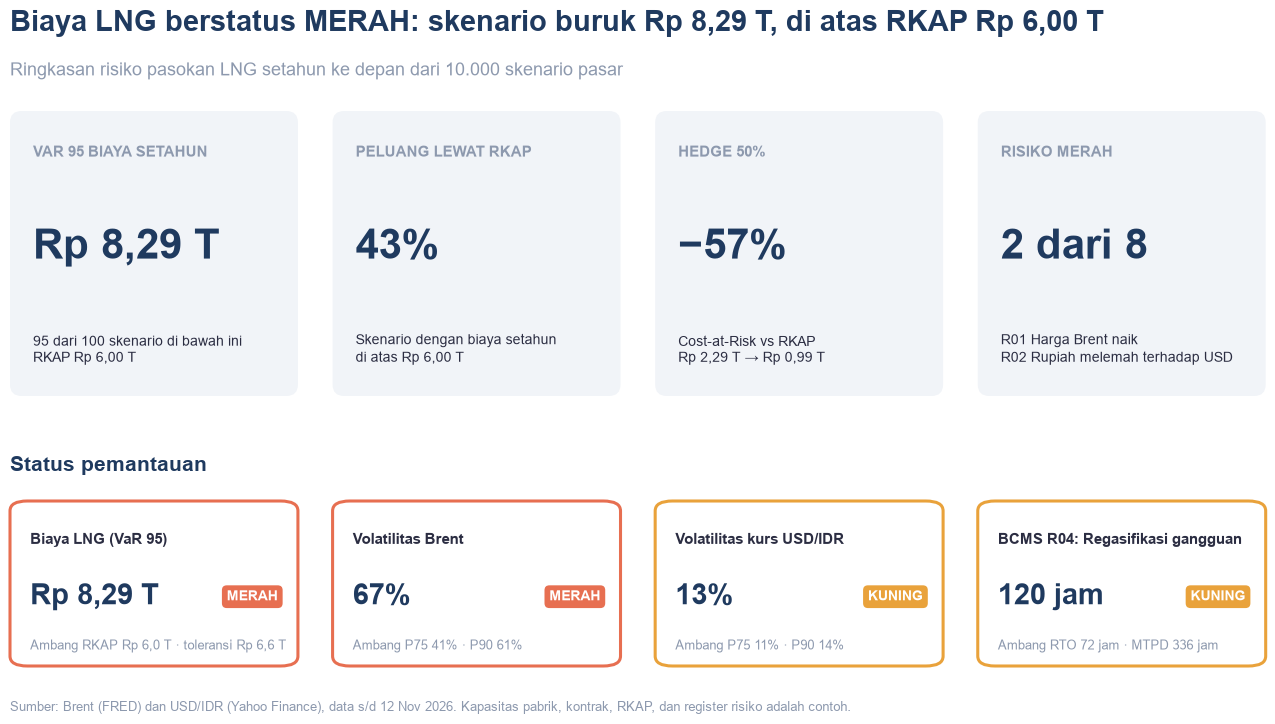

In [8]:
mh, merah = m_hedge, reg[reg.status == "MERAH"]
n_skenario = idn(f"{P['n_sims']:,}")
bc = bcms.iloc[bcms.status.map({"HIJAU": 0, "KUNING": 1, "MERAH": 2}).argmax()]   # skenario BCMS terburuk

fig = slide(f"Biaya LNG berstatus {cost_status}: skenario buruk {rp(m['VaR 95'])}, "
            f"{'di atas' if m['VaR 95'] > P['rkap'] else 'di bawah'} RKAP {rp(P['rkap'])}",
            f"Ringkasan risiko pasokan LNG setahun ke depan dari {n_skenario} skenario pasar")
kpi = [
    ("VaR 95 biaya setahun", rp(m["VaR 95"]), f"95 dari 100 skenario di bawah ini\nRKAP {rp(P['rkap'])}"),
    ("Peluang lewat RKAP", pct(m["P(> RKAP)"]), f"Skenario dengan biaya setahun\ndi atas {rp(P['rkap'])}"),
    (f"Hedge {pct(P['hedge'])}", f"−{pct(1 - mh['CaR vs RKAP'] / m['CaR vs RKAP'])}",
     f"Cost-at-Risk vs RKAP\n{rp(m['CaR vs RKAP'])} → {rp(mh['CaR vs RKAP'])}"),
    ("Risiko merah", f"{len(merah)} dari {len(reg)}", "\n".join(f"{r.id} {pendek(r.risiko)}" for r in merah.itertuples()) or "Tidak ada"),
]
for i, (lab, nilai, ket) in enumerate(kpi):                        # 4 kartu KPI
    a = fig.add_axes([0.03 + i * 0.242, 0.44, 0.216, 0.38]); a.axis("off")
    a.add_patch(FancyBboxPatch((0, 0), 1, 1, boxstyle="round,pad=0,rounding_size=0.04", fc=C["latar"], ec="none",
                               transform=a.transAxes, clip_on=False))
    a.text(0.08, 0.84, lab.upper(), fontsize=10.5, fontweight="bold", color=C["abu"], transform=a.transAxes)
    a.text(0.08, 0.52, nilai, fontsize=30, fontweight="bold", color=C["navy"], va="center", transform=a.transAxes)
    a.text(0.08, 0.12, ket, fontsize=10, color=C["teks"], linespacing=1.35, transform=a.transAxes)

# 4 kartu status: nilai, warna status, dan ambangnya
kartu = [("Biaya LNG (VaR 95)", rp(m["VaR 95"]), cost_status, f"Ambang RKAP {rp(P['rkap'], 1)} · toleransi {rp(batas, 1)}")]
kartu += [(f"Volatilitas {lab}", pct(r["vol 60h sekarang %"] / 100), r["status"],
           f"Ambang P75 {pct(r['P75 %'] / 100)} · P90 {pct(r['P90 %'] / 100)}")
          for lab, (_, r) in zip(["Brent", "kurs USD/IDR"], kri.iterrows())]
kartu += [(f"BCMS {bc.id}: {pendek(bc.skenario)}", f"{bc['estimasi downtime (jam)']} jam", bc.status,
           f"Ambang RTO {bc['RTO (jam)']} jam · MTPD {bc['MTPD (jam)']} jam")]
fig.text(0.03, 0.34, "Status pemantauan", fontsize=15, fontweight="bold", color=C["navy"])
for i, (lab, nilai, st, ambang) in enumerate(kartu):
    a = fig.add_axes([0.03 + i * 0.242, 0.08, 0.216, 0.22]); a.axis("off")
    a.add_patch(FancyBboxPatch((0, 0), 1, 1, boxstyle="round,pad=0,rounding_size=0.06", fc="white",
                               ec=warna_status[st], lw=2.2, transform=a.transAxes, clip_on=False))
    a.text(0.07, 0.74, lab, fontsize=11, fontweight="bold", color=C["teks"], transform=a.transAxes)
    a.text(0.07, 0.42, nilai, fontsize=21, fontweight="bold", color=C["navy"], va="center", transform=a.transAxes)
    a.text(0.93, 0.42, st, fontsize=10, fontweight="bold", color="white", ha="right", va="center",
           transform=a.transAxes, bbox=dict(boxstyle="round,pad=0.35", fc=warna_status[st], ec="none"))
    a.text(0.07, 0.10, ambang, fontsize=9.5, color=C["abu"], transform=a.transAxes)
fig.savefig("images/01_ringkasan.png"); plt.show()

### 6.2 Biaya LNG dan efek hedging

**Biaya LNG 12 bulan, 10.000 skenario**

,Tanpa hedge,Hedge 50%,Perubahan,Arti
Metrik,,,,
Rata-rata biaya,"Rp 5,94 T","Rp 5,83 T",-2%,Perkiraan biaya LNG setahun
VaR 95,"Rp 8,29 T","Rp 6,99 T",-16%,95 dari 100 skenario biayanya di bawah angka ini
CVaR 95,"Rp 9,26 T","Rp 7,45 T",-20%,Rata-rata biaya pada 5% skenario terburuk
Cost-at-Risk vs RKAP,"Rp 2,29 T","Rp 0,99 T",-57%,VaR 95 − RKAP: seberapa jauh anggaran bisa terlampaui
Peluang biaya > RKAP,43%,35%,-19%,Porsi skenario yang melewati anggaran


*Cara membaca:* hedge mengunci harga Brent untuk 50% volume. Rata-rata biaya hampir tidak berubah (-2%), tetapi Cost-at-Risk turun 57%: hedging membeli kepastian anggaran, bukan penghematan. Risiko kurs tidak ikut di-hedge.

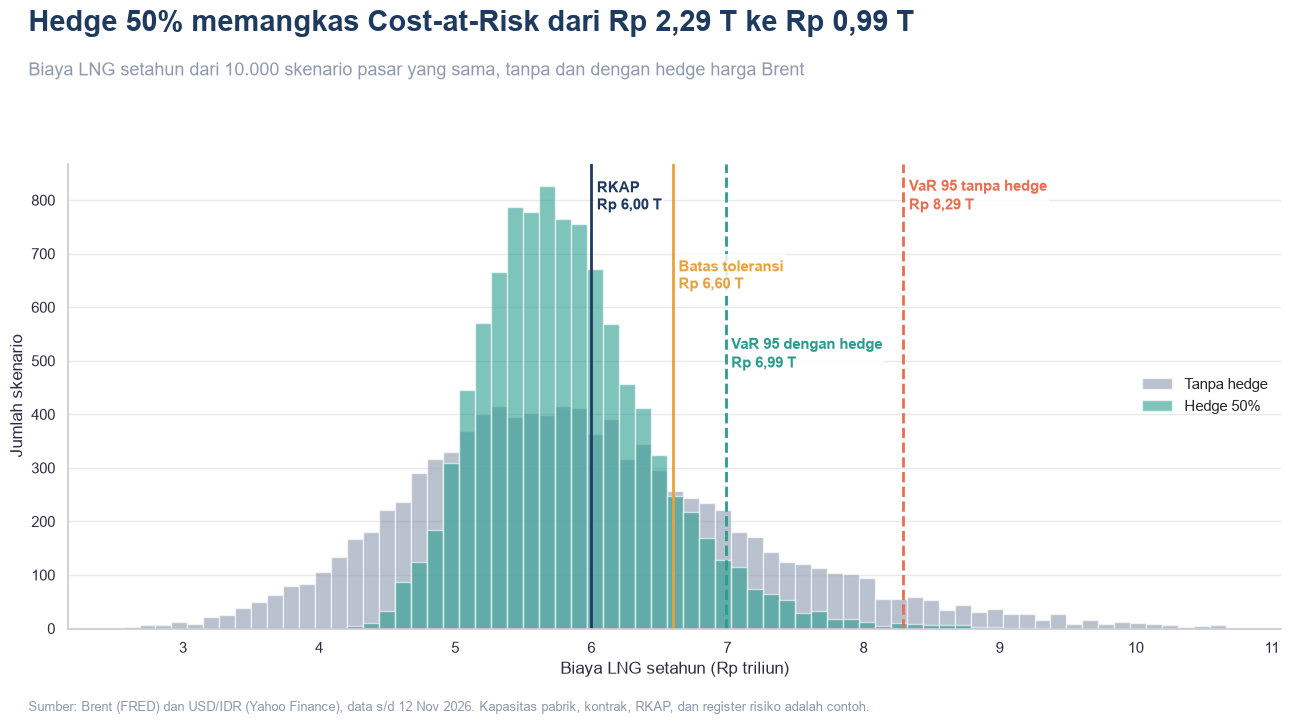

In [9]:
baris = [("Rata-rata biaya", "Mean", "Perkiraan biaya LNG setahun"),
         ("VaR 95", "VaR 95", "95 dari 100 skenario biayanya di bawah angka ini"),
         ("CVaR 95", "CVaR 95", "Rata-rata biaya pada 5% skenario terburuk"),
         ("Cost-at-Risk vs RKAP", "CaR vs RKAP", "VaR 95 − RKAP: seberapa jauh anggaran bisa terlampaui")]
tabel = [(lab, rp(m[k]), rp(mh[k]), pct(mh[k] / m[k] - 1), arti) for lab, k, arti in baris]
tabel += [("Peluang biaya > RKAP", pct(m["P(> RKAP)"]), pct(mh["P(> RKAP)"]), pct(mh["P(> RKAP)"] / m["P(> RKAP)"] - 1),
           "Porsi skenario yang melewati anggaran")]
tampil(f"Biaya LNG 12 bulan, {n_skenario} skenario", pd.DataFrame(
    tabel, columns=["Metrik", "Tanpa hedge", f"Hedge {pct(P['hedge'])}", "Perubahan", "Arti"]).set_index("Metrik"),
    f"hedge mengunci harga Brent untuk {pct(P['hedge'])} volume. Rata-rata biaya hampir tidak berubah "
    f"({pct(mh['Mean'] / m['Mean'] - 1)}), tetapi Cost-at-Risk turun {pct(1 - mh['CaR vs RKAP'] / m['CaR vs RKAP'])}: "
    "hedging membeli kepastian anggaran, bukan penghematan. Risiko kurs tidak ikut di-hedge.")

cost_h = simulate(px, P["hedge"])
fig = slide(f"Hedge {pct(P['hedge'])} memangkas Cost-at-Risk dari {rp(m['CaR vs RKAP'])} ke {rp(mh['CaR vs RKAP'])}",
            f"Biaya LNG setahun dari {n_skenario} skenario pasar yang sama, tanpa dan dengan hedge harga Brent")
ax = fig.add_axes([0.06, 0.13, 0.91, 0.62])
bins = np.linspace(min(cost.min(), cost_h.min()), np.quantile(cost, 0.995), 70)
for c, lab, col in [(cost, "Tanpa hedge", C["abu"]), (cost_h, f"Hedge {pct(P['hedge'])}", C["teal"])]:
    ax.hist(c, bins=bins, color=col, alpha=0.6, label=lab)
ymax = ax.get_ylim()[1]
for (x, lab, col, ls), y in zip([(P["rkap"], f"RKAP\n{rp(P['rkap'])}", C["navy"], "-"),
                                 (batas, f"Batas toleransi\n{rp(batas)}", C["emas"], "-"),
                                 (mh["VaR 95"], f"VaR 95 dengan hedge\n{rp(mh['VaR 95'])}", C["teal"], "--"),
                                 (m["VaR 95"], f"VaR 95 tanpa hedge\n{rp(m['VaR 95'])}", C["merah"], "--")],
                                [0.97, 0.80, 0.63, 0.97]):
    ax.axvline(x, color=col, ls=ls, lw=2)
    ax.text(x + 0.04, ymax * y, lab, va="top", fontsize=11, fontweight="bold", color=col, linespacing=1.3,
            bbox=dict(fc="white", ec="none", alpha=0.85, pad=1.5))
ax.set(xlabel="Biaya LNG setahun (Rp triliun)", ylabel="Jumlah skenario")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: idn(f"{v:g}")))
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: idn(f"{v:,.0f}")))
ax.legend(loc="center right")
fig.savefig("images/02_biaya_hedging.png"); plt.show()

### 6.3 Risk register

**Risk register, diurutkan dari skor tertinggi**

,Risiko,Kategori,Likelihood,Impact,Skor Okt 2026 → Nov 2026,Status,Rekomendasi mitigasi,Owner,Tenggat
id,,,,,,,,,
R01,Harga Brent naik (harga LNG ikut naik),Pasar,4,5,16 → 20,MERAH,Terapkan lindung nilai (hedging) komoditas Brent menggunakan instrumen derivatif seperti swap atau call option secara berkala.,Dept. Pengadaan Gas,2026-12-31
R02,Rupiah melemah terhadap USD,Keuangan,4,4,12 → 16,MERAH,Lakukan transaksi forex hedging (forward/option USD/IDR) dan manfaatkan pendapatan ekspor berbasis USD sebagai natural hedging.,Dept. Treasury,2026-12-31
R03,"Kargo LNG terlambat, pabrik turun rate",Operasional,3,4,12 → 12,KUNING,Tetapkan batas minimum stok tangki LNG (safety stock) dan buat klausul swap kargo darurat dalam kontrak pasokan.,Dept. Operasi Pabrik,2027-03-31
R06,Perubahan kebijakan HGBT / harga gas,Regulasi,3,4,9 → 12,KUNING,Lakukan advokasi berkala dengan kementerian terkait dan terapkan strategi penyesuaian harga jual produk non-subsidi.,Dept. Hukum & Regulasi,2027-03-31
R04,"Regasifikasi gangguan, pabrik amonia stop",Operasional,2,5,10 → 10,KUNING,Terapkan pemeliharaan prediktif berkala pada unit regasifikasi serta sediakan komponen kritis cadangan (redundansi) di fasilitas.,Dept. Operasi Pabrik,2027-06-30
R05,Force majeure pemasok LNG,Pasokan,2,4,12 → 8,KUNING,Susun Master Sales and Purchase Agreement (MSPA) dengan beberapa pemasok alternatif dan klausul pengalihan kargo cadangan.,Dept. Pengadaan Gas,2027-06-30
R07,Tarif sewa kapal LNG naik,Pasar,2,3,9 → 6,HIJAU,-,Dept. Pengadaan Gas,2027-03-31
R08,Gagal bayar pihak lawan,Kredit,1,4,4 → 4,HIJAU,-,Dept. Treasury,2027-06-30


*Cara membaca:* skor = Likelihood × Impact. Hijau ≤ 6, kuning ≤ 12, di atasnya merah. Rekomendasi: salinan rekomendasi Gemini terakhir (data/rekomendasi.json), wajib direview risk owner.

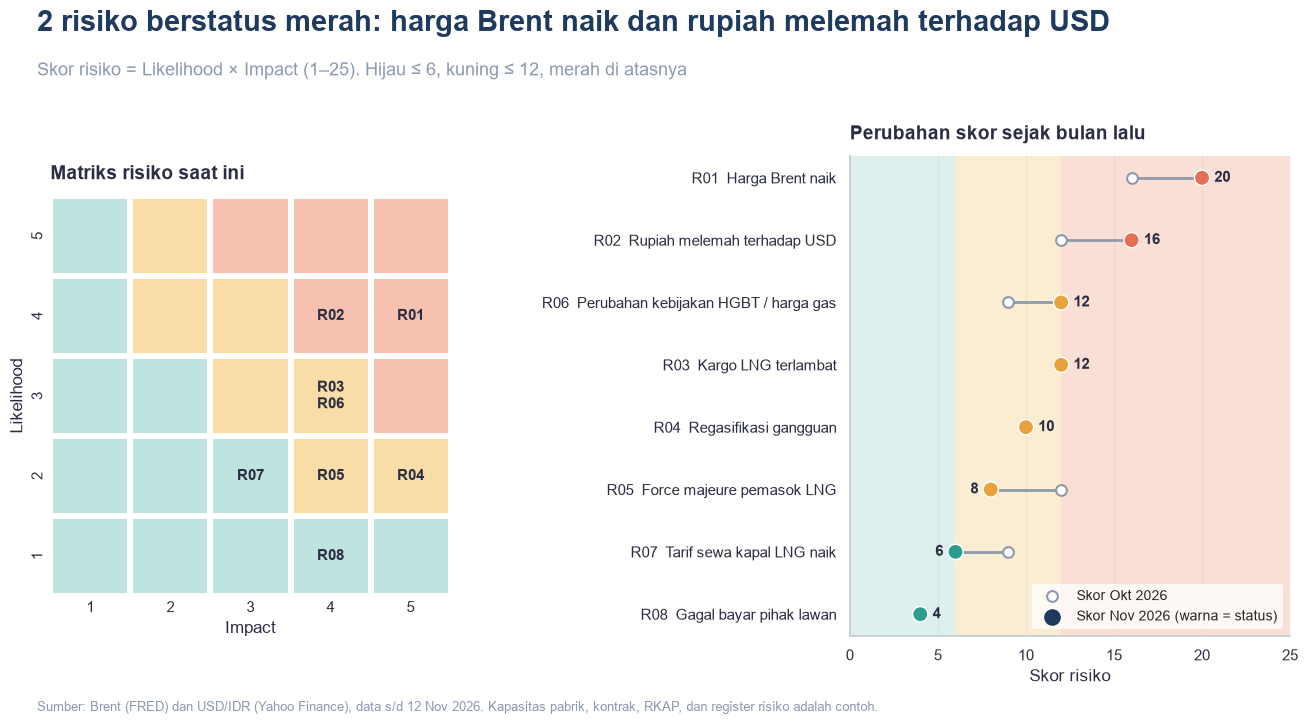

In [10]:
kolom_skor = f"Skor {bln(lalu.index[-1])} → {bln(px.index[-1])}"
tampil("Risk register, diurutkan dari skor tertinggi", (
    reg.sort_values(["skor", "L"], ascending=False).set_index("id")
       .assign(perubahan=lambda d: d.skor_lalu.astype(str) + " → " + d.skor.astype(str))
       [["risiko", "kategori", "L", "I", "perubahan", "status", "rekomendasi", "owner", "tenggat"]]
       .rename(columns={"risiko": "Risiko", "kategori": "Kategori", "L": "Likelihood", "I": "Impact",
                        "perubahan": kolom_skor, "status": "Status", "rekomendasi": "Rekomendasi mitigasi",
                        "owner": "Owner", "tenggat": "Tenggat"})),
    f"skor = Likelihood × Impact. Hijau ≤ {P['appetite']}, kuning ≤ {P['tolerance']}, di atasnya merah. "
    f"Rekomendasi: {sumber_rek}.")

judul = (f"{len(merah)} risiko berstatus merah: " + " dan ".join(pendek(r)[0].lower() + pendek(r)[1:] for r in merah.risiko)
         if len(merah) else "Tidak ada risiko berstatus merah")
fig = slide(judul, f"Skor risiko = Likelihood × Impact (1–25). Hijau ≤ {P['appetite']}, kuning ≤ {P['tolerance']}, merah di atasnya")
ax = fig.subplots(1, 2, gridspec_kw={"width_ratios": [1, 1.1]})
fig.subplots_adjust(top=0.76, bottom=0.12, left=0.04, right=0.97, wspace=0.95)
muda = {"HIJAU": "#BFE3DE", "KUNING": "#F8DDA6", "MERAH": "#F6C1B1"}

# (a) Matriks risiko 5×5
L, I = np.meshgrid(range(5, 0, -1), range(1, 6), indexing="ij")
kode = np.vectorize({"HIJAU": 0, "KUNING": 1, "MERAH": 2}.get)(status(L * I, P["appetite"], P["tolerance"]))
label = [["\n".join(reg.id[(reg.L == l) & (reg.I == i)]) for i in range(1, 6)] for l in range(5, 0, -1)]
sns.heatmap(kode, annot=label, fmt="", cmap=list(muda.values()), cbar=False, vmin=0, vmax=2, square=True,
            linewidths=3, linecolor="white", xticklabels=range(1, 6), yticklabels=range(5, 0, -1),
            annot_kws={"fontsize": 11, "weight": "bold", "color": C["teks"]}, ax=ax[0])
ax[0].set(title="Matriks risiko saat ini", xlabel="Impact", ylabel="Likelihood")
ax[0].tick_params(length=0)

# (b) Perubahan skor sejak bulan lalu
d = reg.sort_values(["skor", "L"])
y = np.arange(len(d))
for lo, hi, st in [(0, P["appetite"], "HIJAU"), (P["appetite"], P["tolerance"], "KUNING"), (P["tolerance"], 25, "MERAH")]:
    ax[1].axvspan(lo, hi, color=muda[st], alpha=0.5, lw=0)
ax[1].hlines(y, d.skor_lalu, d.skor, color=C["abu"], lw=2)
ax[1].scatter(d.skor_lalu, y, color="white", edgecolor=C["abu"], linewidth=1.5, s=60, zorder=3, label=f"Skor {bln(lalu.index[-1])}")
ax[1].scatter(d.skor, y, color=[warna_status[s] for s in d.status], edgecolor="white", s=120, zorder=4)
ax[1].scatter([], [], color=C["navy"], s=120, label=f"Skor {bln(px.index[-1])} (warna = status)")
for yi, now, before in zip(y, d.skor, d.skor_lalu):
    kanan = now >= before
    ax[1].text(now + (0.7 if kanan else -0.7), yi, str(now), va="center", ha="left" if kanan else "right",
               fontsize=11, fontweight="bold", color=C["teks"])
ax[1].set_yticks(y, [f"{r.id}  {pendek(r.risiko)}" for r in d.itertuples()])
ax[1].set(title="Perubahan skor sejak bulan lalu", xlabel="Skor risiko", xlim=(0, 25))
ax[1].grid(axis="x", color="#E6E9ED"); ax[1].grid(axis="y", visible=False)
ax[1].legend(loc="lower right", fontsize=10, frameon=True, facecolor="white", edgecolor="none")
fig.savefig("images/03_register.png"); plt.show()

### 6.4 Pemantauan: KRI dan BCMS

**Perubahan sejak bulan lalu (data s/d 30 Okt 2026)**

,Bulan lalu,Sekarang,Perubahan
Metrik,,,
Rata-rata biaya,"Rp 5,78 T","Rp 5,94 T","+0,16 T"
VaR 95,"Rp 8,10 T","Rp 8,29 T","+0,19 T"
Cost-at-Risk vs RKAP,"Rp 2,10 T","Rp 2,29 T","+0,19 T"
Peluang biaya > RKAP,37%,43%,"+5,7 poin"
Volatilitas Brent,64%,67%,"+2,7 poin"
Volatilitas kurs USD/IDR,8%,13%,"+5,0 poin"


*Cara membaca:* semua metrik dihitung ulang dengan data sampai akhir bulan lalu. Kenaikan biaya, VaR, atau volatilitas berarti risiko memburuk. Volatilitas dalam % per tahun.

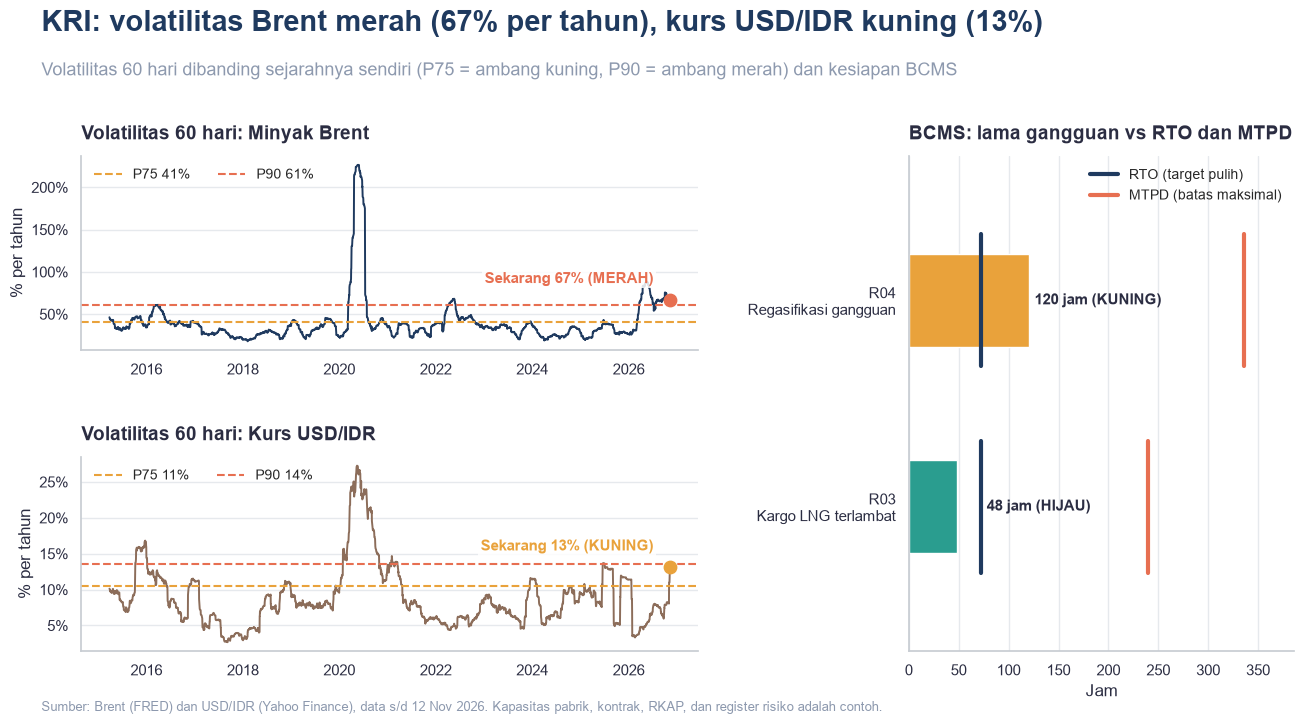

In [11]:
rp_tanda = lambda x: idn(f"{x:+.2f} T")
baris = [("Rata-rata biaya", m_lalu["Mean"], m["Mean"], rp), ("VaR 95", m_lalu["VaR 95"], m["VaR 95"], rp),
         ("Cost-at-Risk vs RKAP", m_lalu["CaR vs RKAP"], m["CaR vs RKAP"], rp),
         ("Peluang biaya > RKAP", m_lalu["P(> RKAP)"], m["P(> RKAP)"], pct),
         ("Volatilitas Brent", v_lalu["brent"], vol60["brent"].iloc[-1], pct),
         ("Volatilitas kurs USD/IDR", v_lalu["usdidr"], vol60["usdidr"].iloc[-1], pct)]
tampil(f"Perubahan sejak bulan lalu (data s/d {tgl(lalu.index[-1])})", pd.DataFrame(
    [(lab, f(a), f(b), rp_tanda(b - a) if f is rp else idn(f"{(b - a) * 100:+.1f} poin")) for lab, a, b, f in baris],
    columns=["Metrik", "Bulan lalu", "Sekarang", "Perubahan"]).set_index("Metrik"),
    "semua metrik dihitung ulang dengan data sampai akhir bulan lalu. Kenaikan biaya, VaR, atau volatilitas "
    "berarti risiko memburuk. Volatilitas dalam % per tahun.")

st_b, st_u = kri.status["brent"], kri.status["usdidr"]
fig = slide(f"KRI: volatilitas Brent {st_b.lower()} ({pct(vol60['brent'].iloc[-1])} per tahun), "
            f"kurs USD/IDR {st_u.lower()} ({pct(vol60['usdidr'].iloc[-1])})",
            "Volatilitas 60 hari dibanding sejarahnya sendiri (P75 = ambang kuning, P90 = ambang merah) dan kesiapan BCMS")
ax = fig.subplot_mosaic([["brent", "bcms"], ["usdidr", "bcms"]], gridspec_kw={"width_ratios": [1.6, 1]})
fig.subplots_adjust(top=0.76, bottom=0.1, left=0.06, right=0.97, hspace=0.55, wspace=0.42)
for k in ["brent", "usdidr"]:
    a, v, st = ax[k], vol60[k] * 100, kri.status[k]
    a.plot(v.index, v, color=warna[k], lw=1.4)
    a.axhline(q.loc[.75, k] * 100, color=C["emas"], ls="--", lw=1.5, label=f"P75 {pct(q.loc[.75, k])}")
    a.axhline(q.loc[.90, k] * 100, color=C["merah"], ls="--", lw=1.5, label=f"P90 {pct(q.loc[.90, k])}")
    a.scatter(v.index[-1], v.iloc[-1], color=warna_status[st], s=80, zorder=5)
    a.annotate(f"Sekarang {pct(v.iloc[-1] / 100)} ({st})", (v.index[-1], v.iloc[-1]), xytext=(-12, 12),
               textcoords="offset points", ha="right", fontsize=11, fontweight="bold", color=warna_status[st],
               bbox=dict(fc="white", ec="none", alpha=0.85, pad=1.5))
    a.set(title=f"Volatilitas 60 hari: {nama[k]}", ylabel="% per tahun")
    a.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: idn(f"{x:.0f}%")))
    a.legend(loc="upper left", ncol=2, fontsize=10)

# BCMS: lama gangguan dibanding RTO dan MTPD
b, a = bcms.iloc[::-1].reset_index(drop=True), ax["bcms"]
a.barh(b.index, b["estimasi downtime (jam)"], height=0.45, color=[warna_status[s] for s in b.status])
for yi, r in b.iterrows():
    a.text(max(r["estimasi downtime (jam)"], r["RTO (jam)"]) + 6, yi, f"{r['estimasi downtime (jam)']} jam ({r.status})", va="center",
           fontsize=11, fontweight="bold", color=C["teks"])
    for x, col in [(r["RTO (jam)"], C["navy"]), (r["MTPD (jam)"], C["merah"])]:
        a.plot([x, x], [yi - 0.32, yi + 0.32], color=col, lw=3)
a.plot([], [], color=C["navy"], lw=3, label="RTO (target pulih)")
a.plot([], [], color=C["merah"], lw=3, label="MTPD (batas maksimal)")
a.set_yticks(b.index, [f"{r.id}\n{pendek(r.skenario)}" for r in b.itertuples()])
a.set(title="BCMS: lama gangguan vs RTO dan MTPD", xlabel="Jam", xlim=(0, b["MTPD (jam)"].max() * 1.15), ylim=(-0.7, len(b) - 0.3))
a.grid(axis="x", color="#E6E9ED"); a.grid(axis="y", visible=False)
a.legend(loc="upper right", fontsize=10)
fig.savefig("images/04_pemantauan.png"); plt.show()

### 6.5 Data pasar

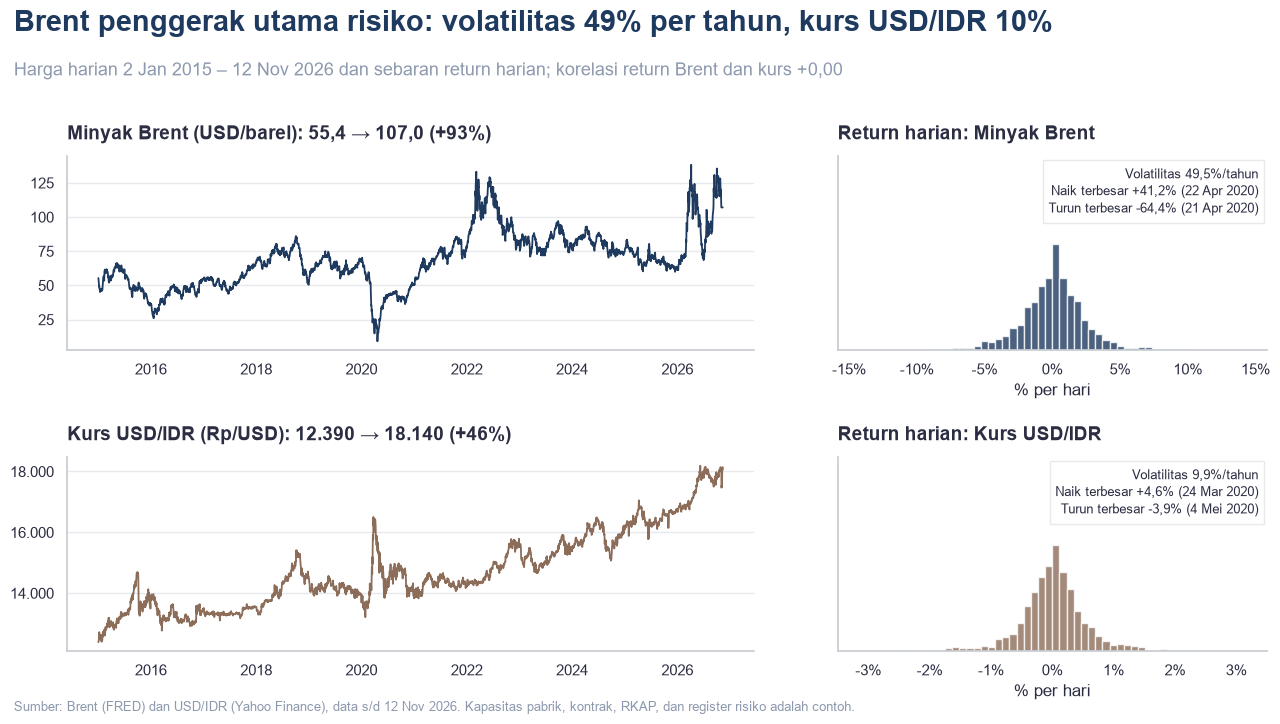

In [12]:
vol = ret.std() * np.sqrt(252)
fig = slide(f"Brent penggerak utama risiko: volatilitas {pct(vol['brent'])} per tahun, kurs USD/IDR {pct(vol['usdidr'])}",
            f"Harga harian {tgl(px.index[0])} – {tgl(px.index[-1])} dan sebaran return harian; "
            f"korelasi return Brent dan kurs {idn(f'{ret.corr().iloc[0, 1]:+.2f}')}")
ax = fig.subplot_mosaic([["hbrent", "rbrent"], ["husdidr", "rusdidr"]], gridspec_kw={"width_ratios": [1.6, 1]})
fig.subplots_adjust(top=0.76, bottom=0.1, left=0.07, right=0.97, hspace=0.55, wspace=0.15)
for k, cur, unit, d in [("brent", "USD", "barel", 1), ("usdidr", "Rp", "USD", 0)]:
    s, a = px[k], ax[f"h{k}"]
    v0, v1 = s.iloc[[0, -1]]
    a.plot(s.index, s, color=warna[k], lw=1.3)
    a.set(title=idn(f"{nama[k]} ({cur}/{unit}): {v0:,.{d}f} → {v1:,.{d}f} ({v1 / v0 - 1:+.0%})"))
    a.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: idn(f"{x:,.0f}")))

    r, a = ret[k] * 100, ax[f"r{k}"]
    lim = np.quantile(r.abs(), 0.995) * 1.2                          # potong ekor ekstrem agar badan sebaran terlihat
    a.hist(r, bins=np.linspace(-lim, lim, 61), color=warna[k], alpha=0.8)
    a.set(title=f"Return harian: {nama[k]}", xlabel="% per hari", yticks=[], xlim=(-lim, lim))
    a.set_ylim(top=a.get_ylim()[1] * 1.75)                           # ruang untuk kotak keterangan
    a.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: idn(f"{x:g}%")))
    a.text(0.98, 0.95, idn(f"Volatilitas {vol[k] * 100:.1f}%/tahun\nNaik terbesar {r.max():+.1f}% ({tgl(r.idxmax())})\n"
                           f"Turun terbesar {r.min():+.1f}% ({tgl(r.idxmin())})"),
           transform=a.transAxes, ha="right", va="top", fontsize=9.5, color=C["teks"], linespacing=1.4,
           bbox=dict(fc="white", ec="#E6E9ED", pad=4))
fig.savefig("images/05_data_pasar.png"); plt.show()